# 15 · Perfect-supplier replenishment: JEPA planner vs tuned textbook rules

The world has one shop, four products, and one perfect supplier: what the shop pays for arrives in full after the delivery lag. Only demand is uncertain, and the shop sees sales, not demand (ADR 0033, `src/perfect_supplier/README.md`).

**Arms.** Every arm runs closed-loop on its own copy of each eval world, with the same demand path. Comparisons are therefore paired world by world.

| arm | what it is |
| --- | --- |
| `jepa` | planner + JEPA quantile forecaster (the learned buyer) |
| `direct` | planner + the same network without the JEPA latent loss (ablation) |
| `planner_moving_average` | planner + 28-day moving-average normal forecast (no learning) |
| `planner_oracle` | planner + the true expected demand path and CV (ceiling; not a real policy) |
| `tuned_order_up_to`, `tuned_reorder_point`, `tuned_periodic_order_up_to`, `tuned_periodic_reorder` | the four engine textbook rules, each tuned **once** across 64 tune worlds. They do not read the order fee or the holding rate |
| `tuned_eoq` | textbook continuous-review (s,Q) with the economic order quantity. It reads the fee and holding rate, as the planner does, and is tuned once like the others |
| `tuned_eoq_joint` | the same rule with a joint trigger: when any product is below its reorder point, every product orders, and the EOQ fee is shared. This is the planner's ordering pattern without the forecast |
| `default_order_up_to` | the engine's default (s,S) |
| `never_order` | floor |

**Score** is margin capture: Δequity / ((price − cost) × total demand). 1.0 means every demanded unit was sold with no fee and no holding cost.

**Three worlds.** Sections 1–8 use the base world (four products, order fee 50). There, the planner's main edge is ordering all four products on one day and paying one fee. That is a real saving, but it is not what the forecaster is for. Sections 9–11 rerun the comparison in two worlds where the fee cannot separate the policies:
- `one_product`: product 0 of each base world, alone; fee 50
- `no_fee`: the base world with the fee set to 0

Data lives under `ROOTS`. Run the commands in the README first if it is empty.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.perfect_supplier import data, analysis
from src.perfect_supplier.analysis import LABELS

ROOTS = {
    "base": REPO / "runs" / "perfect-supplier",
    "one_product": REPO / "runs" / "perfect-supplier-one_product",
    "no_fee": REPO / "runs" / "perfect-supplier-no_fee",
}
ROOT = ROOTS["base"]
pd.set_option("display.width", 200, "display.max_columns", 60)

## 1 · The summary frame

One row per (world, arm). It holds the world's parameters (`variant`, `delivery_lag`, `holding_rate`, `cv`, `weekly_amp`, `capacity`, `initial_cash`, `order_fee`), per-product `base_mean_p*` and `initial_on_hand_p*`, realised `mean_demand_p*`, `zero_demand_days_p*`, `mean_order_qty_p*`, `order_count_p*`, and `fill_rate_p*`. It also holds the outcome: `score`, `delta_equity`, `net_profit`, `revenue`, `fees`, `holding_cost`, `lost_units`, and `order_days` (days with any filled order). `split` is `train` (behaviour log), `eval` (final comparison), or `shadow`.

In [2]:
summary = data.load_summary(ROOT)
print(summary.groupby(["split", "method"]).size().rename("worlds").to_string())
summary.head(3).T

split   method                    
eval    default_order_up_to            500
        direct                         500
        jepa                           500
        never_order                    500
        planner_moving_average         500
        planner_oracle                 500
        tuned_eoq                      500
        tuned_eoq_joint                500
        tuned_order_up_to              500
        tuned_periodic_order_up_to     500
        tuned_periodic_reorder         500
        tuned_reorder_point            500
shadow  jepa                            12
train   behavior                      2000


,0,1,2
method,default_order_up_to,default_order_up_to,default_order_up_to
world_seed,3000000,3000001,3000002
split,eval,eval,eval
n_days,365,365,365
delivery_lag,7,5,6
...,...,...,...
order_count_p3,25,22,22
fill_rate_p3,1.0,0.997375,0.994245
mean_on_hand_p3,35.443836,164.887671,84.654795
behavior,default_order_up_to,default_order_up_to,default_order_up_to


## 2 · Base world: paired comparison on the eval worlds

The baseline is the tuned textbook rule with the best score **on the tune worlds** (`tuning/best_scores.json`), so it is not picked on the worlds it is compared on. `diff_vs_baseline` is the mean world-by-world difference in score, with a 95% bootstrap interval. `win_rate` is the share of worlds where the arm beats the baseline.

In [3]:
ev = summary[summary["split"] == "eval"]
tuned = sorted(m for m in ev["method"].unique() if m.startswith("tuned_"))
BASELINE = analysis.best_textbook(ROOT)
print("baseline:", BASELINE)
table = analysis.paired_table(summary, BASELINE)
(table.assign(**{c: table[c] * 100 for c in ["diff_vs_baseline", "ci_low", "ci_high"]})
      .rename(columns={"diff_vs_baseline": "diff (pts)", "ci_low": "ci low (pts)", "ci_high": "ci high (pts)"})
      .round(3))

baseline: tuned_eoq_joint


,mean_score,diff (pts),ci low (pts),ci high (pts),win_rate,n_worlds
arm,,,,,,
planner_oracle,0.963,0.778,0.735,0.823,1.000,500
direct,0.959,0.407,0.377,0.437,0.944,500
jepa,0.959,0.404,0.374,0.433,0.938,500
planner_moving_average,0.956,0.052,0.023,0.081,0.572,500
tuned_eoq_joint,0.955,0.000,0.000,0.000,0.000,500
tuned_eoq,0.938,-1.704,-1.768,-1.642,0.000,500
tuned_periodic_order_up_to,0.934,-2.096,-2.163,-2.032,0.000,500
tuned_reorder_point,0.929,-2.616,-2.730,-2.502,0.000,500
tuned_order_up_to,0.929,-2.617,-2.728,-2.504,0.000,500


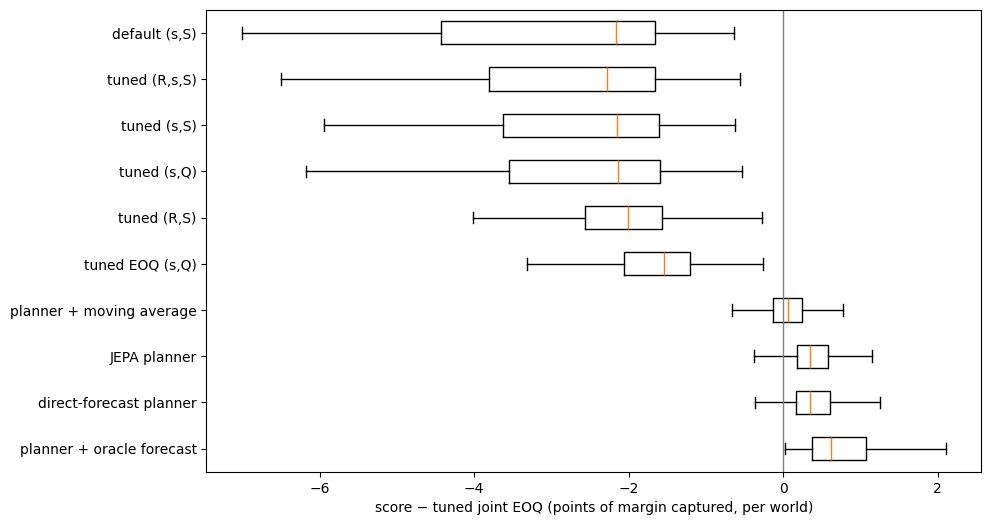

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
analysis.plot_paired(summary, BASELINE, arms=[a for a in table.index if a != "never_order"], ax=ax);

Pairwise against **every** tuned textbook rule, and JEPA against its own ablations. The planner + moving-average arm separates the planner's value from the forecast's value.

In [5]:
m = analysis.score_matrix(summary)
PAIRS = [("jepa", t) for t in tuned] + [("jepa", "direct"), ("jepa", "planner_moving_average"), ("planner_oracle", "jepa")]
analysis.pairwise(summary, PAIRS).round(3)

,arm,vs,diff (pts),ci low,ci high,win rate,n_worlds
0,jepa,tuned_eoq,2.107,2.034,2.181,1.000,500
1,jepa,tuned_eoq_joint,0.404,0.374,0.433,0.938,500
2,jepa,tuned_order_up_to,3.020,2.897,3.143,1.000,500
3,jepa,tuned_periodic_order_up_to,2.500,2.434,2.567,1.000,500
4,jepa,tuned_periodic_reorder,3.107,2.978,3.230,1.000,500
5,jepa,tuned_reorder_point,3.020,2.892,3.147,1.000,500
6,jepa,direct,-0.003,-0.017,0.012,0.492,500
7,jepa,planner_moving_average,0.352,0.321,0.383,0.894,500
8,planner_oracle,jepa,0.375,0.348,0.403,0.986,500


## 3 · Where the margin goes

Each arm's lost margin is split into lost sales, order fees, and holding cost, each as a share of the margin on all demand. The three shares and the score add to exactly 1. In the base world the planner arms order on about half as many days as the engine rules: one fee buys four products. `tuned_eoq_joint` orders the same way without a forecast, so it shows how much of the planner's lead is that pattern. Sections 9–11 remove the fee altogether.

In [6]:
analysis.breakdown(summary).round(4)

,score,lost_sales,fees_share,holding_share,order_days,fill_rate_demand,mean_on_hand
method,,,,,,,
planner_oracle,0.9629,0.0032,0.0141,0.0198,47.248,0.9968,73.6913
direct,0.9592,0.0049,0.0148,0.0211,49.530,0.9951,78.2922
jepa,0.9592,0.0049,0.0148,0.0212,49.348,0.9951,78.5080
planner_moving_average,0.9556,0.0083,0.0150,0.0210,50.026,0.9917,79.2281
tuned_eoq_joint,0.9551,0.0051,0.0185,0.0213,61.768,0.9949,81.0019
tuned_eoq,0.9381,0.0049,0.0291,0.0279,96.700,0.9951,102.9610
tuned_periodic_order_up_to,0.9342,0.0164,0.0228,0.0266,72.992,0.9836,72.7525
tuned_reorder_point,0.9290,0.0055,0.0278,0.0378,89.560,0.9945,102.8515
tuned_order_up_to,0.9290,0.0054,0.0282,0.0375,90.800,0.9946,102.1229


## 4 · Which worlds the learned buyer wins

Mean paired difference to the baseline, cut by world parameters.

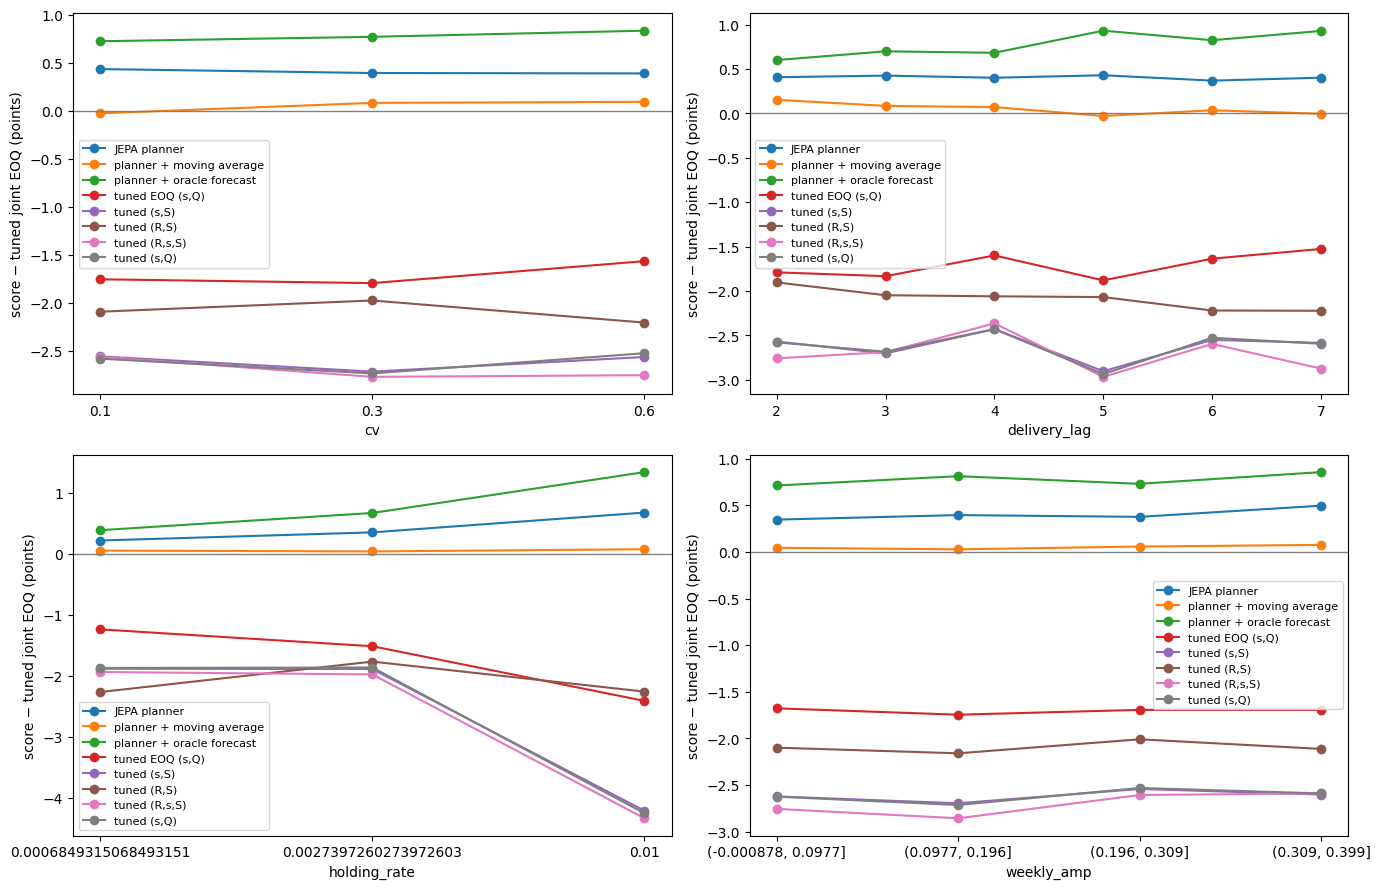

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
arms = ["jepa", "planner_moving_average", "planner_oracle"] + [t for t in tuned if t != BASELINE]
for ax, feat in zip(axes.flat, ["cv", "delivery_lag", "holding_rate", "weekly_amp"]):
    analysis.plot_by_world_feature(summary, BASELINE, feat, arms, ax=ax)
fig.tight_layout()

## 5 · The forecaster

Training curves from `models/*_fit.json`. `pinball` is the censored loss on held-out **sales** (what the model trains on). `pinball_true_demand` is scored against true demand, which the model never sees. That number is inflated by stretches where a behaviour policy left the shelf empty for weeks: demand there cannot be identified from sales by any forecaster.

The same two fitted models drive the planner in all three worlds. They forecast demand only, and the demand process is identical in every variant, so nothing about the fee or the product count is learned.

,step,pinball,pinball_true_demand,coverage
9,20000,0.089285,0.407049,"[0.025631427764892578, 0.09595143049955368, 0...."


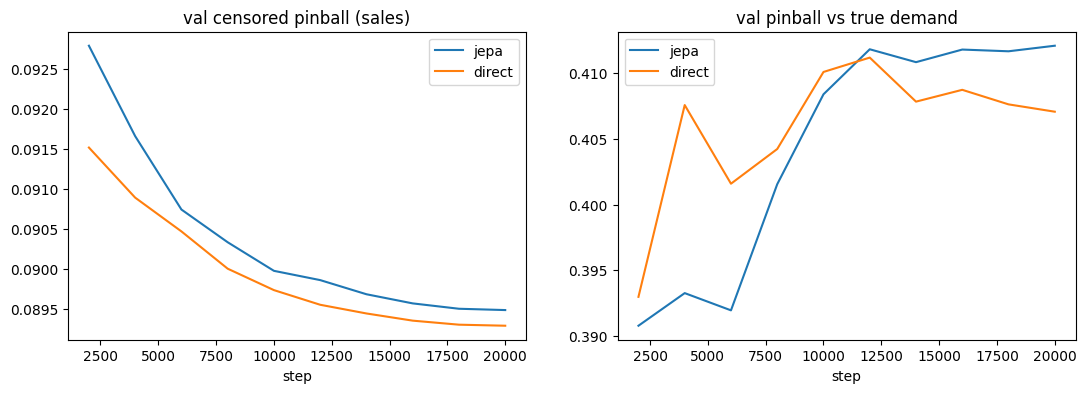

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for arm in ["jepa", "direct"]:
    path = ROOT / "models" / f"{arm}_fit.json"
    if not path.exists():
        continue
    h = pd.DataFrame(json.loads(path.read_text())["history"])
    ax[0].plot(h["step"], h["pinball"], label=arm)
    ax[1].plot(h["step"], h["pinball_true_demand"], label=arm)
ax[0].set_title("val censored pinball (sales)"); ax[1].set_title("val pinball vs true demand")
for a in ax: a.legend(); a.set_xlabel("step")
h.iloc[-1:][["step", "pinball", "pinball_true_demand", "coverage"]]

## 6 · One world, every arm on its own run

Change `SEED`, `PRODUCT`, `ARMS`, and `DAYS`. By default the seed is the world where JEPA loses most to the baseline. Look there first for illogical decisions.

In [9]:
diff = (m["jepa"] - m[BASELINE]).sort_values()
print("JEPA worst worlds:\n", (diff.head(5) * 100).round(2).to_string())
print("JEPA best worlds:\n", (diff.tail(5) * 100).round(2).to_string())
SEED = int(diff.index[0])
PRODUCT = 0
ARMS = ["jepa", BASELINE, "planner_oracle"]
DAYS = (0, 120)
ts = data.load_timeseries(ROOT, split="eval", method=ARMS, world_seed=SEED)
ev[ev["world_seed"] == SEED].set_index("method")[["score", "order_days", "fees", "holding_cost", "lost_units", "delivery_lag", "cv", "holding_rate"]].loc[ARMS]

JEPA worst worlds:
 world_seed
3000398   -0.37
3000085   -0.30
3000255   -0.29
3000063   -0.25
3000355   -0.21
JEPA best worlds:
 world_seed
3000422    1.31
3000349    1.42
3000409    1.64
3000385    1.72
3000206    1.88


,score,order_days,fees,holding_cost,lost_units,delivery_lag,cv,holding_rate
method,,,,,,,,
jepa,0.974341,26,1300.0,1756.767123,187,7,0.6,0.000685
tuned_eoq_joint,0.978082,31,1550.0,1588.445205,107,7,0.6,0.000685
planner_oracle,0.980687,25,1250.0,1558.321918,90,7,0.6,0.000685


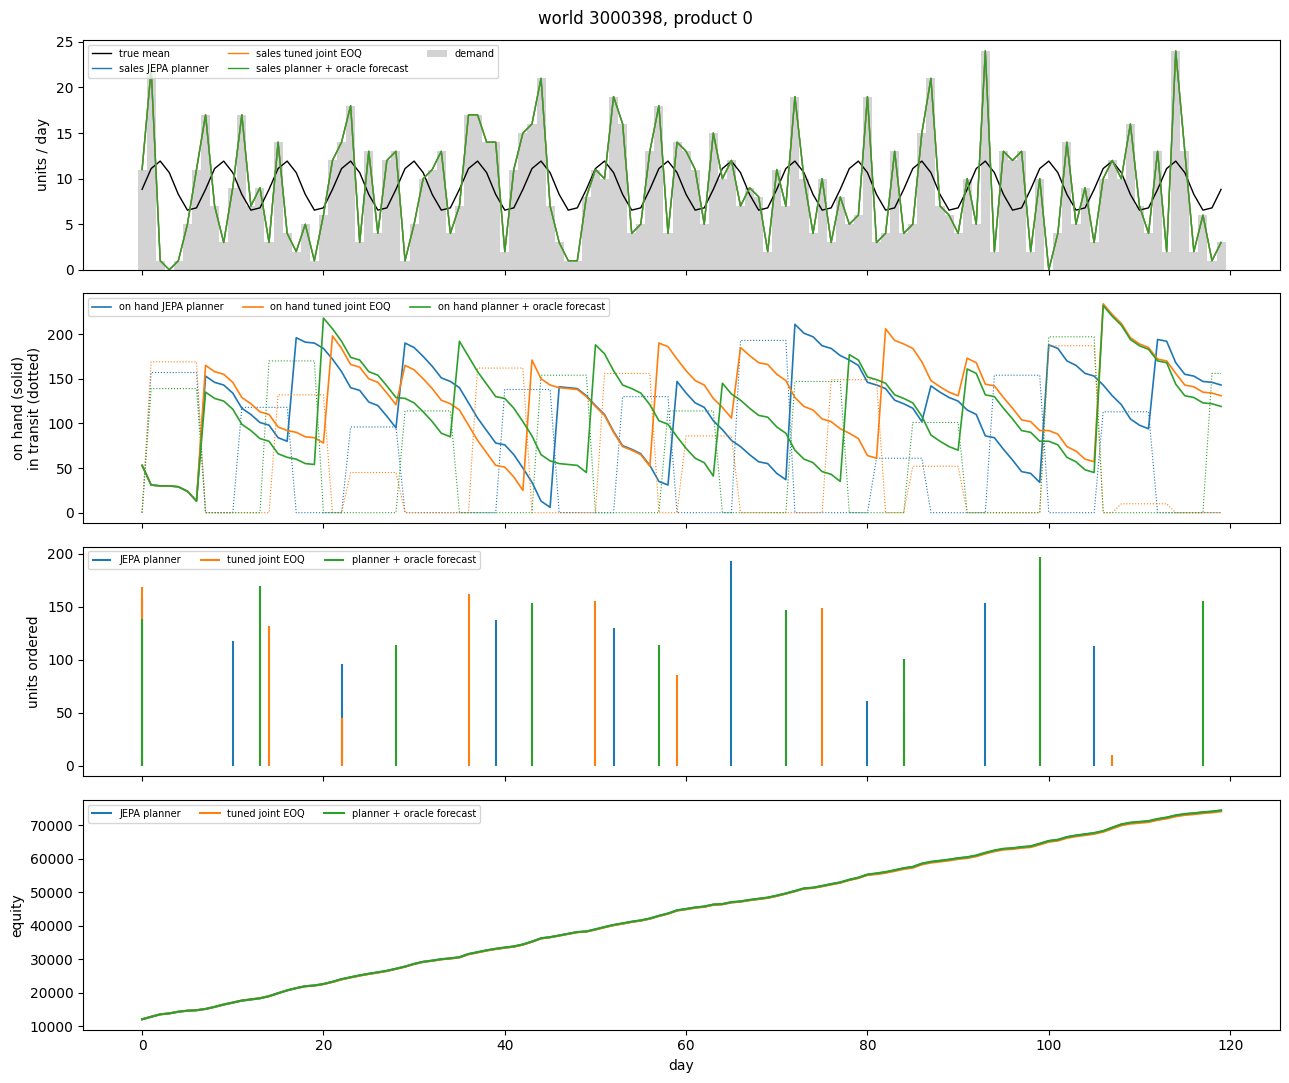

In [10]:
analysis.plot_world(ts, SEED, PRODUCT, ARMS, days=DAYS);

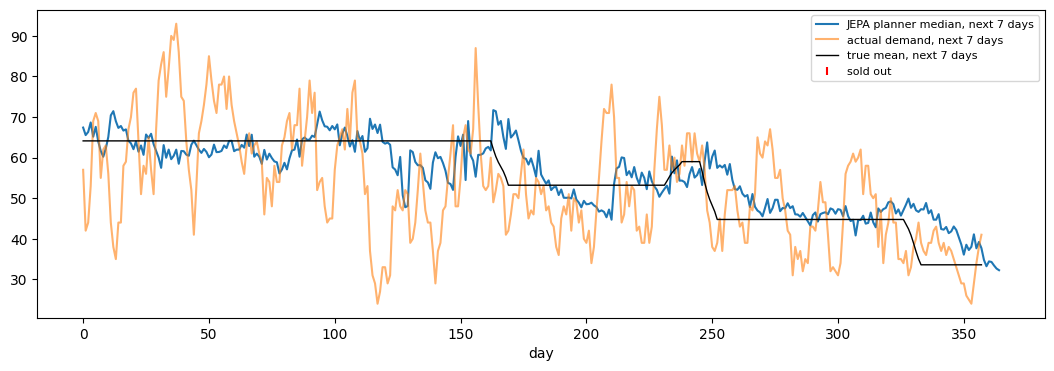

In [11]:
analysis.plot_forecast(ts, SEED, PRODUCT, "jepa");

The JEPA arm's decision columns (`dec_*`) per day:
- `dec_review`, `dec_service`: the winning plan
- `dec_order_today`: whether that plan orders today
- `dec_score`: its imagined Δequity over 35 days
- `dec_score_best_wait`, `dec_score_best_order`: the best plan that waits vs the best that orders
- `dec_forecast_mean_7d`: the median forecast summed over the next 7 days

In [12]:
cols = ["day", "product", "demand", "sales", "on_hand_close", "in_transit", "requested", "filled",
        "dec_review", "dec_service", "dec_order_today", "dec_score", "dec_score_best_wait", "dec_score_best_order", "dec_forecast_mean_7d"]
ts[(ts["method"] == "jepa") & (ts["product"] == PRODUCT)][cols].head(30)

,day,product,demand,sales,on_hand_close,in_transit,requested,filled,dec_review,dec_service,dec_order_today,dec_score,dec_score_best_wait,dec_score_best_order,dec_forecast_mean_7d
0,0,0,11,11,53,0,157,157,21.0,0.90,True,18335.541631,NaN,18335.541631,67.407784
4,1,0,22,22,31,157,0,0,21.0,0.90,False,17844.644264,17844.644264,NaN,65.554283
8,2,0,1,1,30,157,0,0,21.0,0.80,False,18168.697560,18168.697560,NaN,66.326584
12,3,0,0,0,30,157,0,0,21.0,0.80,False,18198.024508,18198.024508,NaN,68.667984
16,4,0,1,1,29,157,0,0,21.0,0.90,False,18789.488228,18789.488228,NaN,65.159317
20,5,0,5,5,24,157,0,0,21.0,0.90,False,19441.737265,19441.737265,NaN,67.592628
24,6,0,11,11,13,157,0,0,14.0,0.95,False,19522.423052,19522.423052,NaN,63.977730
28,7,0,17,17,153,0,0,0,21.0,0.80,False,19359.069884,19359.069884,NaN,61.639225
32,8,0,7,7,146,0,0,0,14.0,0.95,False,19157.021404,19157.021404,19112.126070,60.230145
36,9,0,3,3,143,0,0,0,21.0,0.90,False,19472.307256,19472.307256,19459.674658,62.223183


## 7 · Shadow run: same state, every arm's decision

`split=shadow`: JEPA drives the shop. On every day the oracle planner and the tuned textbook rules read the **same** observation, and what they would have requested is logged (`shadow_<arm>_requested`). Nothing they ask for is executed.

,planner_oracle,tuned_periodic_order_up_to,tuned_eoq,tuned_eoq_joint,jepa (driver)
orders on same day (share of driver order days),0.89,0.19,0.59,0.94,1.00
mean units when ordering,88.70,67.72,155.40,84.56,88.24
order days per product-year,57.19,55.48,43.19,74.58,54.38


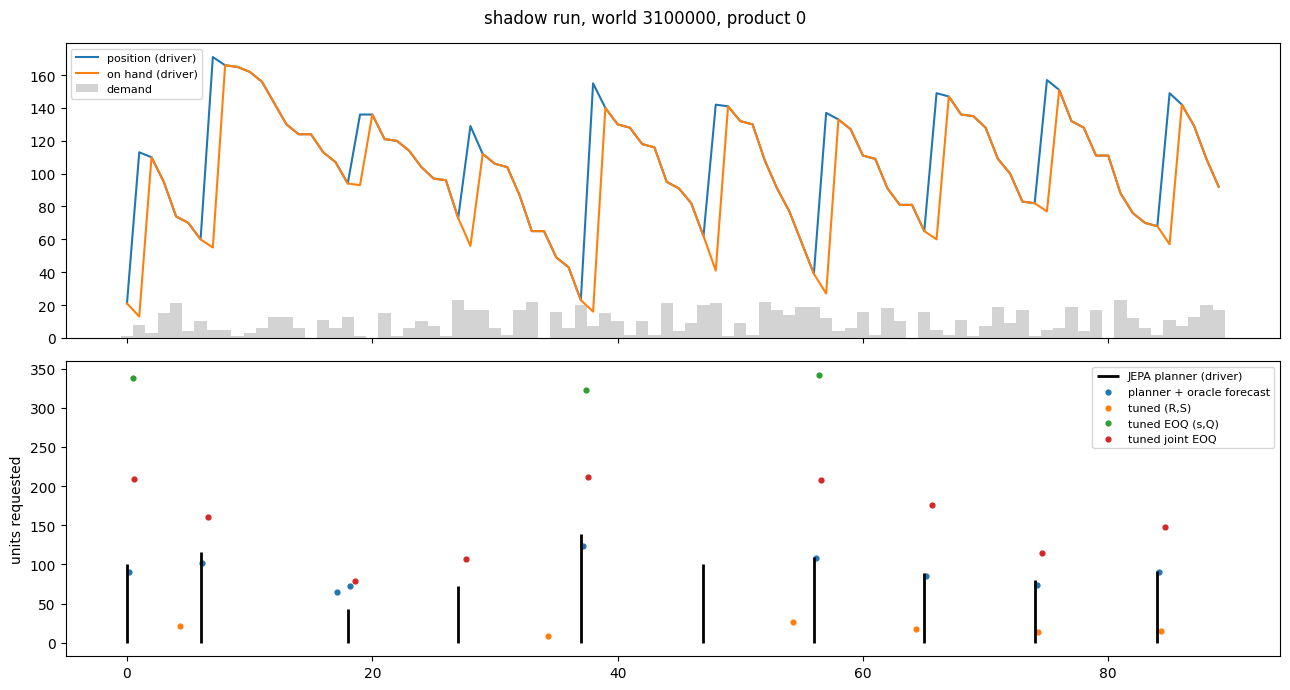

In [13]:
def shadow_agreement(root):
    sh = data.load_timeseries(root, split="shadow")
    if not len(sh):
        return sh, None
    shadow_cols = [c for c in sh.columns if c.startswith("shadow_")]
    agree = pd.DataFrame({
        c.removeprefix("shadow_").removesuffix("_requested"): {
            "orders on same day (share of driver order days)": ((sh[c] > 0) & (sh["requested"] > 0)).sum() / max((sh["requested"] > 0).sum(), 1),
            "mean units when ordering": sh.loc[sh[c] > 0, c].mean(),
            "order days per product-year": (sh[c] > 0).groupby([sh["world_seed"], sh["product"]]).sum().mean(),
        } for c in shadow_cols})
    agree["jepa (driver)"] = [1.0, sh.loc[sh["requested"] > 0, "requested"].mean(), (sh["requested"] > 0).groupby([sh["world_seed"], sh["product"]]).sum().mean()]
    return sh, agree.round(2)

sh, agree = shadow_agreement(ROOT)
if agree is not None:
    display(agree)
    analysis.plot_shadow(sh, int(sh["world_seed"].iloc[0]), 0, days=(0, 90))

## 8 · The detailed time-series frame

Every simulation is stored, training and evaluation alike: one row per day × product, partitioned by `split` and `method` under `timeseries/`. Read any slice without loading the rest:

```python
data.load_timeseries(ROOT, split="eval", method="jepa", world_seed=[3000000, 3000001])
data.load_timeseries(ROOT, split="train", columns=["world_seed", "day", "product", "demand", "sales", "censored"])
```

Columns:
- **Per product:** `demand`, `demand_mean` (truth, never shown to policies), `sales`, `lost`, `censored`, `on_hand_open`, `arrivals`, `in_transit`, `position`, `requested`, `filled`, `on_hand_close`
- **Shop, repeated on each product row:** `cash_open`, `cash_close`, `purchase_cost`, `fee_paid`, `revenue`, `holding_cost`, `equity_close`
- **Decisions:** `dec_*` for each arm's decision columns, `shadow_*` for shadow requests
- **Training log only:** `behavior` names the policy that ran the shop

The two variant roots have the same layout, without a training log: their arms reuse the base models.

In [14]:
print(sorted(p.name for p in (ROOT / "timeseries").glob("split=*/method=*")))
example = data.load_timeseries(ROOT, split="eval", method="jepa", world_seed=SEED)
print(example.shape)
example.head()

['method=behavior', 'method=default_order_up_to', 'method=direct', 'method=jepa', 'method=jepa', 'method=never_order', 'method=planner_moving_average', 'method=planner_oracle', 'method=tuned_eoq', 'method=tuned_eoq_joint', 'method=tuned_order_up_to', 'method=tuned_periodic_order_up_to', 'method=tuned_periodic_reorder', 'method=tuned_reorder_point']
(1460, 33)


,world_seed,day,weekday,product,on_hand_open,arrivals,in_transit,position,requested,filled,demand,demand_mean,sales,lost,censored,on_hand_close,cash_open,cash_close,purchase_cost,fee_paid,revenue,holding_cost,equity_close,dec_review,dec_service,dec_order_today,dec_score,dec_score_best_wait,dec_score_best_order,dec_forecast_mean_7d,behavior,split,method
0,3000398,0,0,0,64,0,0,53,157,157,11,8.824458,11,0,False,53,7633.790049,1.591419,8800.0,50.0,1220.0,2.198630,12011.591419,21,0.9,True,18335.541631,NaN,18335.541631,67.407784,jepa,eval,jepa
1,3000398,0,0,1,127,0,0,113,272,272,14,17.493862,14,0,False,113,7633.790049,1.591419,8800.0,50.0,1220.0,2.198630,12011.591419,21,0.9,True,18335.541631,NaN,18335.541631,121.406960,jepa,eval,jepa
2,3000398,0,0,2,65,0,0,61,148,148,4,10.341934,4,0,False,61,7633.790049,1.591419,8800.0,50.0,1220.0,2.198630,12011.591419,21,0.9,True,18335.541631,NaN,18335.541631,65.253532,jepa,eval,jepa
3,3000398,0,0,3,126,0,0,94,303,303,32,17.272464,32,0,False,94,7633.790049,1.591419,8800.0,50.0,1220.0,2.198630,12011.591419,21,0.9,True,18335.541631,NaN,18335.541631,128.913712,jepa,eval,jepa
4,3000398,1,1,0,53,0,157,188,0,0,22,11.107178,22,0,False,31,1.591419,1499.906488,0.0,0.0,1500.0,1.684932,12759.906488,21,0.9,False,17844.644264,17844.644264,NaN,65.554283,jepa,eval,jepa


## 9 · Taking the order fee out of the comparison

In the base world, two things that have nothing to do with forecasting favour the planner:

1. **Joint ordering.** The planner orders all four products on one day and pays one fee. The engine rules trigger per product, so they pay up to four fees for the same goods. `tuned_eoq_joint` closes this gap in the base world.
2. **Knowing the economics.** The planner's imagined recursion charges the real fee and holding rate, so it sizes orders to the world. The four engine rules never read either number, and one parameter set has to fit every holding rate.

Two variants and one extra baseline remove both:

| world | products | fee | what can still separate policies |
| --- | --- | --- | --- |
| `one_product` | 1 (product 0 of the base world: same lag, cv, holding rate, and demand path) | 50 | when to order and how much; no fee to share |
| `no_fee` | 4 (the base world) | 0 | lost sales vs holding only; ordering every day is free |

- **`tuned_eoq`** is textbook (s,Q) with the EOQ order quantity `sqrt(2·fee·rate / (holding_rate·cost))` and safety stock `z·sd·sqrt(lag)`. It reads the same fee and holding rate the planner reads. With no fee, Q = 0 and it becomes a daily base-stock rule. `tuned_eoq_joint` is its joint-trigger version.
- **Tuning.** Every textbook rule is re-tuned on each variant's own tune worlds (200 trials, 64 worlds).
- **Forecasters.** The planner arms reuse the base forecasters unchanged (section 5).

If the JEPA planner still beats the best textbook rule here, the edge comes from forecasting and per-world planning, not from the fee.

In [15]:
summaries = {v: data.load_summary(r) for v, r in ROOTS.items()}
summaries = {v: s for v, s in summaries.items() if len(s)}

def variant_report(variant):
    s = summaries[variant]
    base = analysis.best_textbook(ROOTS[variant])
    t = analysis.paired_table(s, base)
    t = (t.assign(**{c: t[c] * 100 for c in ["diff_vs_baseline", "ci_low", "ci_high"]})
          .rename(columns={"diff_vs_baseline": "diff (pts)", "ci_low": "ci low (pts)", "ci_high": "ci high (pts)"}))
    tuned_v = sorted(x for x in s.loc[s["split"] == "eval", "method"].unique() if x.startswith("tuned_"))
    pairs = analysis.pairwise(s, [("jepa", x) for x in tuned_v] + [("jepa", "direct"), ("jepa", "planner_moving_average"), ("planner_oracle", "jepa")])
    return base, t.round(3), pairs.round(3), analysis.breakdown(s).round(4)

### 9a · One product, fee 50

best textbook rule: tuned_eoq_joint


,mean_score,diff (pts),ci low (pts),ci high (pts),win_rate,n_worlds
arm,,,,,,
planner_oracle,0.927,0.284,0.229,0.340,0.740,500
direct,0.925,0.068,0.021,0.115,0.544,500
jepa,0.925,0.062,0.016,0.108,0.534,500
tuned_eoq_joint,0.925,0.000,0.000,0.000,0.000,500
tuned_eoq,0.925,-0.000,-0.030,0.030,0.420,500
planner_moving_average,0.923,-0.174,-0.223,-0.127,0.346,500
tuned_order_up_to,0.918,-0.666,-0.744,-0.589,0.158,500
tuned_periodic_reorder,0.918,-0.682,-0.771,-0.599,0.156,500
tuned_reorder_point,0.918,-0.685,-0.766,-0.604,0.170,500


,arm,vs,diff (pts),ci low,ci high,win rate,n_worlds
0,jepa,tuned_eoq,0.062,0.019,0.107,0.542,500
1,jepa,tuned_eoq_joint,0.062,0.016,0.108,0.534,500
2,jepa,tuned_order_up_to,0.728,0.650,0.807,0.860,500
3,jepa,tuned_periodic_order_up_to,5.544,5.320,5.773,1.000,500
4,jepa,tuned_periodic_reorder,0.744,0.656,0.836,0.850,500
5,jepa,tuned_reorder_point,0.747,0.672,0.822,0.864,500
6,jepa,direct,-0.006,-0.035,0.024,0.502,500
7,jepa,planner_moving_average,0.237,0.191,0.284,0.706,500
8,planner_oracle,jepa,0.222,0.185,0.261,0.676,500


,score,lost_sales,fees_share,holding_share,order_days,fill_rate_demand,mean_on_hand
method,,,,,,,
planner_oracle,0.9275,0.0036,0.0409,0.0281,29.638,0.9964,81.6600
direct,0.9253,0.0055,0.0401,0.0290,29.274,0.9945,83.9479
jepa,0.9252,0.0056,0.0402,0.0290,29.260,0.9944,83.8982
tuned_eoq_joint,0.9246,0.0053,0.0388,0.0312,28.894,0.9947,90.4449
tuned_eoq,0.9246,0.0042,0.0392,0.0320,29.228,0.9958,91.9183
planner_moving_average,0.9229,0.0079,0.0403,0.0290,29.274,0.9921,84.3630
tuned_order_up_to,0.9180,0.0053,0.0397,0.0371,28.326,0.9947,93.9631
tuned_periodic_reorder,0.9178,0.0051,0.0378,0.0393,27.448,0.9949,98.2039
tuned_reorder_point,0.9178,0.0042,0.0409,0.0371,29.198,0.9958,94.0696


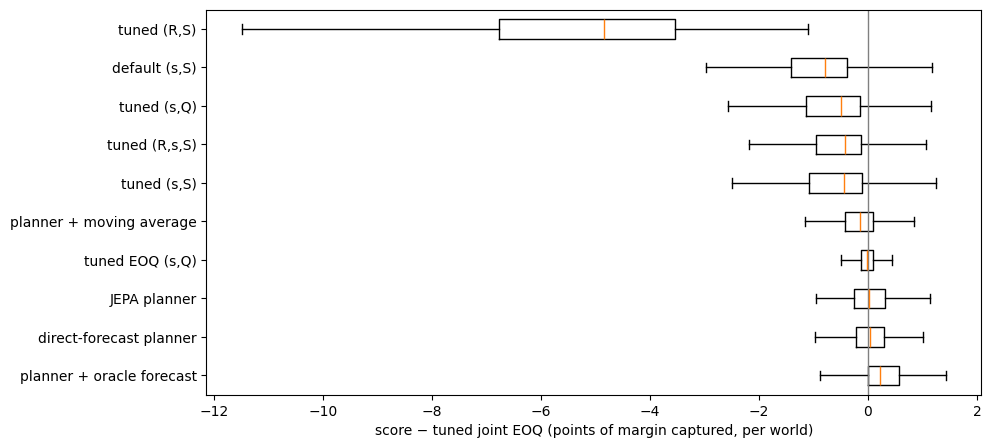

In [16]:
if "one_product" in summaries:
    base1, t1, p1, b1 = variant_report("one_product")
    print("best textbook rule:", base1)
    display(t1); display(p1); display(b1)
    fig, ax = plt.subplots(figsize=(10, 5))
    analysis.plot_paired(summaries["one_product"], base1, arms=[a for a in t1.index if a != "never_order"], ax=ax)

### 9b · Four products, no fee

best textbook rule: tuned_eoq_joint


,mean_score,diff (pts),ci low (pts),ci high (pts),win_rate,n_worlds
arm,,,,,,
planner_oracle,0.989,0.674,0.623,0.727,0.948,500
tuned_eoq_joint,0.982,0.000,0.000,0.000,0.000,500
tuned_eoq,0.982,-0.001,-0.001,0.000,0.348,500
direct,0.982,-0.040,-0.079,-0.000,0.402,500
jepa,0.982,-0.050,-0.091,-0.010,0.388,500
tuned_periodic_order_up_to,0.980,-0.256,-0.304,-0.209,0.334,500
tuned_reorder_point,0.978,-0.391,-0.447,-0.335,0.244,500
tuned_order_up_to,0.978,-0.417,-0.471,-0.362,0.228,500
tuned_periodic_reorder,0.976,-0.633,-0.721,-0.551,0.222,500


,arm,vs,diff (pts),ci low,ci high,win rate,n_worlds
0,jepa,tuned_eoq,-0.050,-0.091,-0.009,0.390,500
1,jepa,tuned_eoq_joint,-0.050,-0.091,-0.010,0.388,500
2,jepa,tuned_order_up_to,0.366,0.291,0.442,0.596,500
3,jepa,tuned_periodic_order_up_to,0.206,0.144,0.267,0.552,500
4,jepa,tuned_periodic_reorder,0.583,0.481,0.690,0.588,500
5,jepa,tuned_reorder_point,0.340,0.267,0.414,0.586,500
6,jepa,direct,-0.010,-0.021,0.002,0.454,500
7,jepa,planner_moving_average,0.652,0.601,0.703,0.914,500
8,planner_oracle,jepa,0.725,0.684,0.766,0.970,500


,score,lost_sales,fees_share,holding_share,order_days,fill_rate_demand,mean_on_hand
method,,,,,,,
planner_oracle,0.9890,0.0037,0.0,0.0072,355.020,0.9963,20.7044
tuned_eoq_joint,0.9823,0.0047,0.0,0.0130,364.952,0.9953,34.6342
tuned_eoq,0.9823,0.0047,0.0,0.0131,364.962,0.9953,34.7772
direct,0.9819,0.0101,0.0,0.0080,350.732,0.9899,23.6840
jepa,0.9818,0.0102,0.0,0.0080,350.792,0.9898,23.5780
tuned_periodic_order_up_to,0.9797,0.0065,0.0,0.0138,364.906,0.9935,37.7380
tuned_reorder_point,0.9784,0.0056,0.0,0.0160,338.720,0.9944,43.8665
tuned_order_up_to,0.9781,0.0047,0.0,0.0172,352.458,0.9953,46.9697
tuned_periodic_reorder,0.9760,0.0032,0.0,0.0208,348.806,0.9968,57.1360


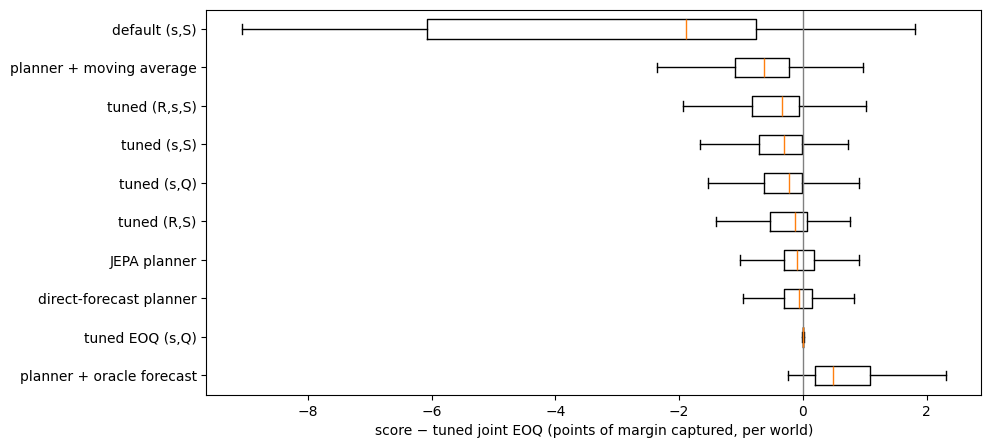

In [17]:
if "no_fee" in summaries:
    base0, t0, p0, b0 = variant_report("no_fee")
    print("best textbook rule:", base0)
    display(t0); display(p0); display(b0)
    fig, ax = plt.subplots(figsize=(10, 5))
    analysis.plot_paired(summaries["no_fee"], base0, arms=[a for a in t0.index if a != "never_order"], ax=ax)

### 9c · Which variant worlds JEPA wins and loses

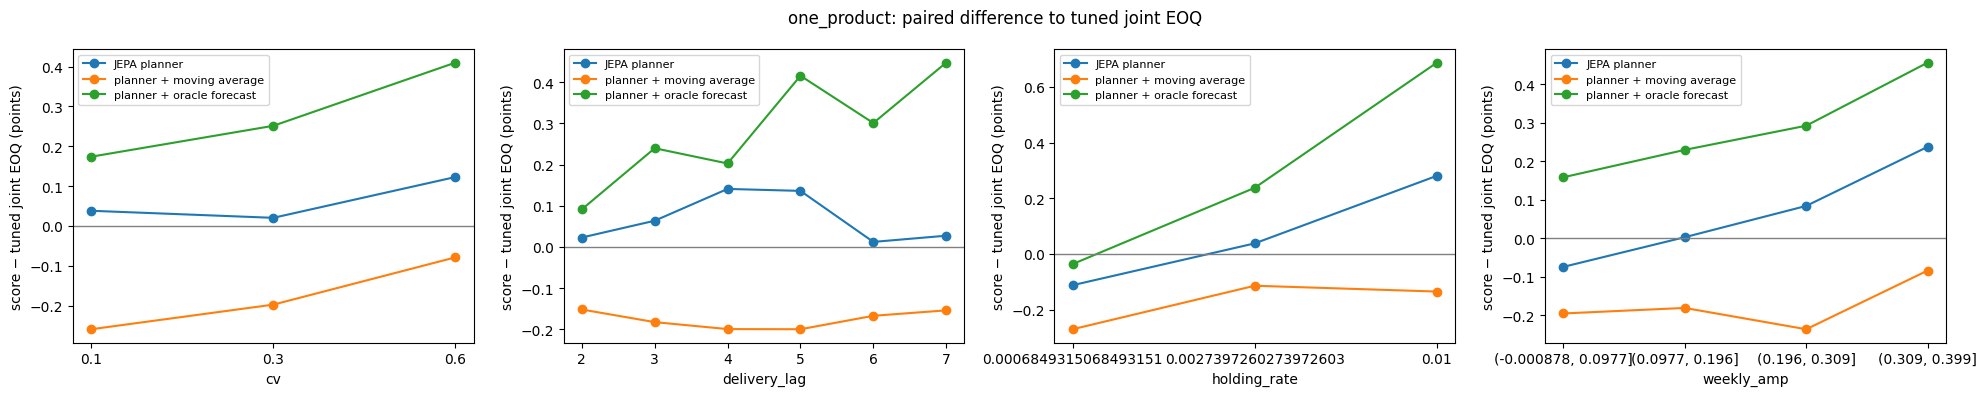

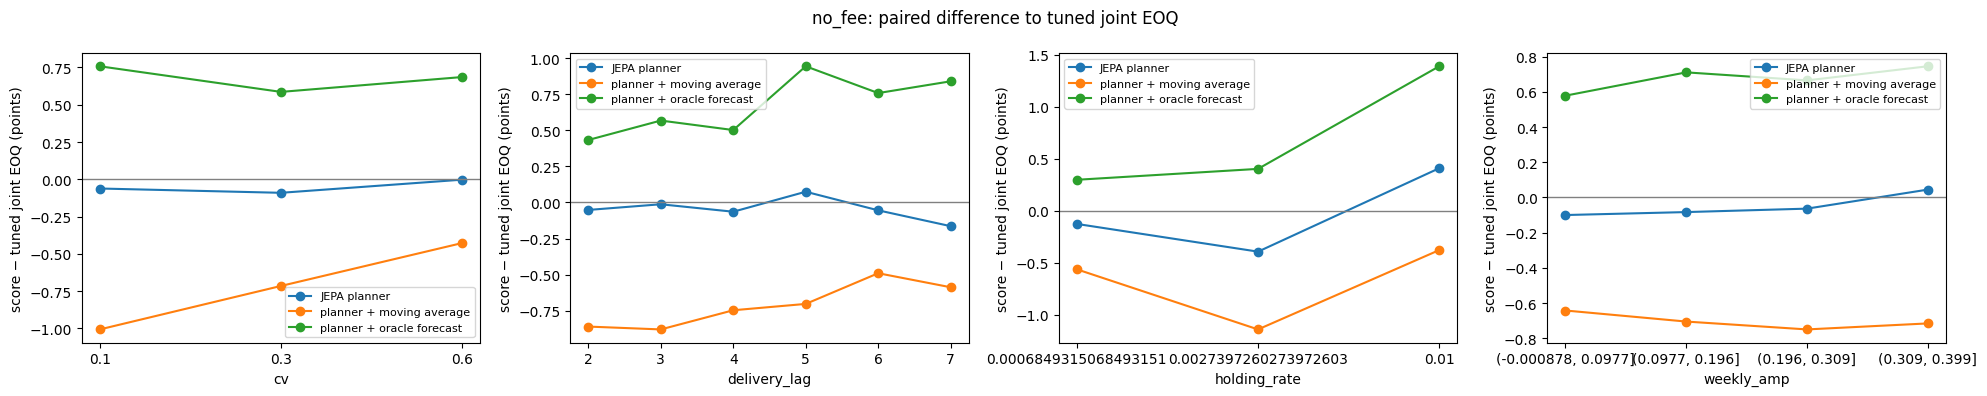

In [18]:
for v in ["one_product", "no_fee"]:
    if v not in summaries:
        continue
    s = summaries[v]
    b = analysis.best_textbook(ROOTS[v])
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for ax, feat in zip(axes, ["cv", "delivery_lag", "holding_rate", "weekly_amp"]):
        analysis.plot_by_world_feature(s, b, feat, ["jepa", "planner_moving_average", "planner_oracle"], ax=ax)
    fig.suptitle(f"{v}: paired difference to {LABELS.get(b, b)}")
    fig.tight_layout()

## 10 · All three worlds side by side

Mean score per arm in each world (points), and each planner arm's paired difference to the best textbook rule of that world. The second table also compares JEPA with the best EOQ rule, the textbook rule that reads the same economics as the planner.

In [19]:
scores = pd.DataFrame({v: s[s["split"] == "eval"].groupby("method")["score"].mean() for v, s in summaries.items()})
display((scores * 100).round(2).sort_values("base", ascending=False).rename(index=lambda a: LABELS.get(a, a)))

rows = []
for v, s in summaries.items():
    b = analysis.best_textbook(ROOTS[v])
    for a in ["jepa", "direct", "planner_moving_average", "planner_oracle"]:
        r = analysis.pairwise(s, [(a, b)]).iloc[0]
        rows.append({"world": v, "arm": LABELS.get(a, a), "vs": LABELS.get(b, b), **r.drop(["arm", "vs"]).to_dict()})
    for e in ["tuned_eoq", "tuned_eoq_joint"]:
        if e != b:
            r = analysis.pairwise(s, [("jepa", e)]).iloc[0]
            rows.append({"world": v, "arm": LABELS["jepa"], "vs": LABELS[e], **r.drop(["arm", "vs"]).to_dict()})
pd.DataFrame(rows).round(3)

,base,one_product,no_fee
method,,,
planner + oracle forecast,96.29,92.75,98.90
direct-forecast planner,95.92,92.53,98.19
JEPA planner,95.92,92.52,98.18
planner + moving average,95.56,92.29,97.53
tuned joint EOQ,95.51,92.46,98.23
"tuned EOQ (s,Q)",93.81,92.46,98.23
"tuned (R,S)",93.42,86.98,97.97
"tuned (s,S)",92.90,91.80,97.81
"tuned (s,Q)",92.90,91.78,97.84


,world,arm,vs,diff (pts),ci low,ci high,win rate,n_worlds
0,base,JEPA planner,tuned joint EOQ,0.404,0.374,0.433,0.938,500
1,base,direct-forecast planner,tuned joint EOQ,0.407,0.377,0.437,0.944,500
2,base,planner + moving average,tuned joint EOQ,0.052,0.023,0.081,0.572,500
3,base,planner + oracle forecast,tuned joint EOQ,0.778,0.735,0.823,1.000,500
4,base,JEPA planner,"tuned EOQ (s,Q)",2.107,2.034,2.181,1.000,500
5,one_product,JEPA planner,tuned joint EOQ,0.062,0.016,0.108,0.534,500
6,one_product,direct-forecast planner,tuned joint EOQ,0.068,0.021,0.115,0.544,500
7,one_product,planner + moving average,tuned joint EOQ,-0.174,-0.223,-0.127,0.346,500
8,one_product,planner + oracle forecast,tuned joint EOQ,0.284,0.229,0.340,0.740,500
9,one_product,JEPA planner,"tuned EOQ (s,Q)",0.062,0.019,0.107,0.542,500


## 11 · Inspecting a variant world

The same plots as sections 6 and 7, for a variant. Set `VARIANT`. The default world is the one where JEPA loses most to that world's best textbook rule.

,score,order_days,fees,holding_cost,lost_units,delivery_lag,cv,holding_rate
method,,,,,,,,
jepa,0.965126,364,0.0,1641.616438,478,6,0.6,0.00274
tuned_eoq_joint,0.976877,365,0.0,2527.835616,173,6,0.6,0.00274
planner_oracle,0.979857,364,0.0,1509.178082,220,6,0.6,0.00274


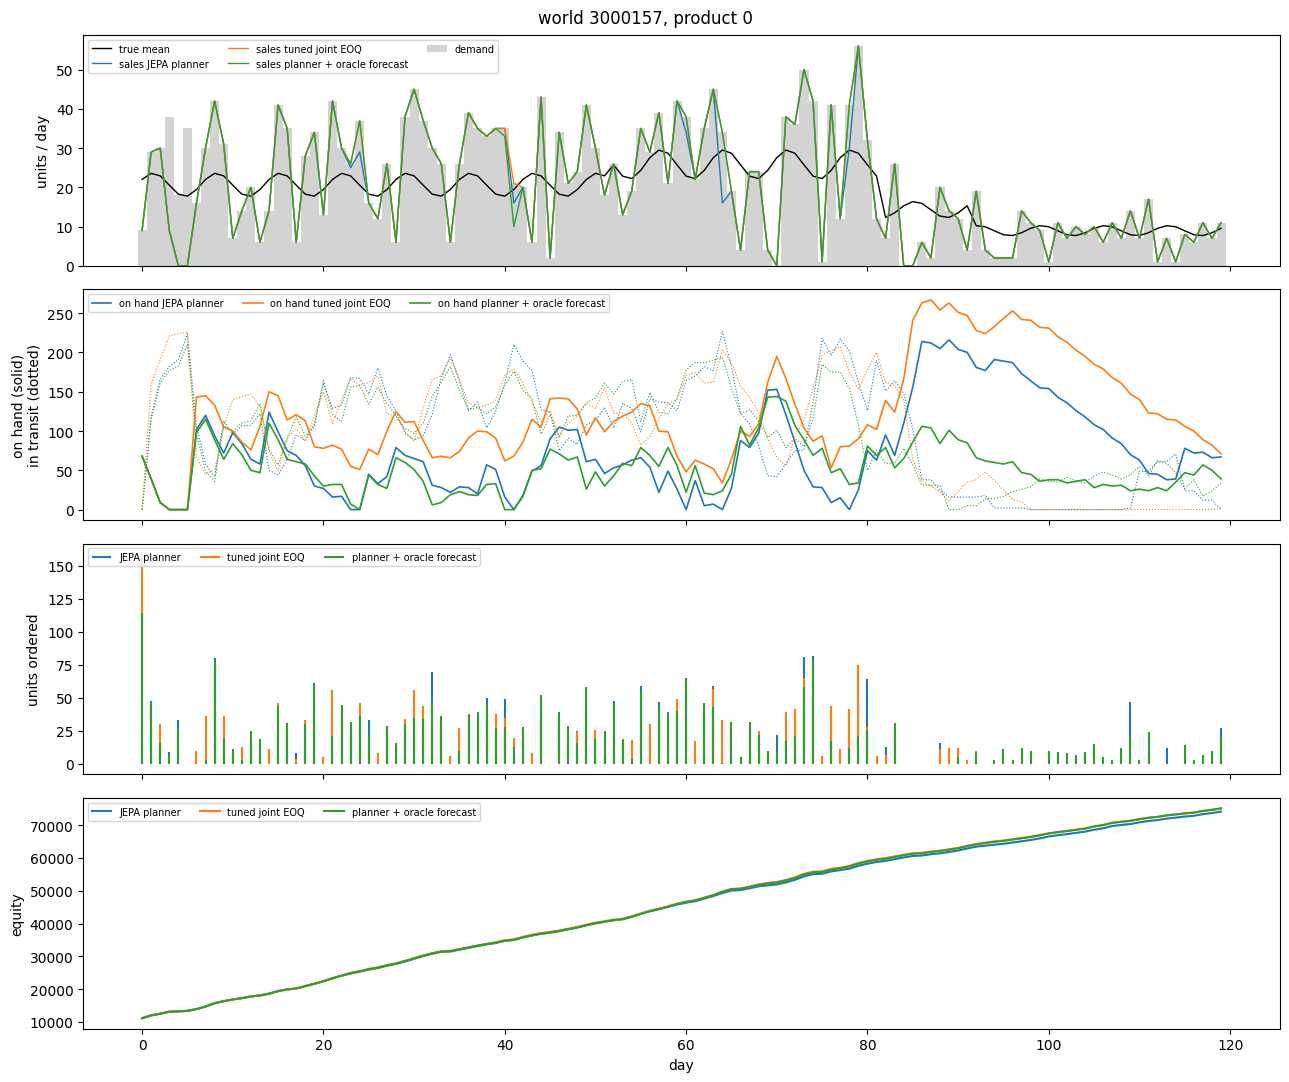

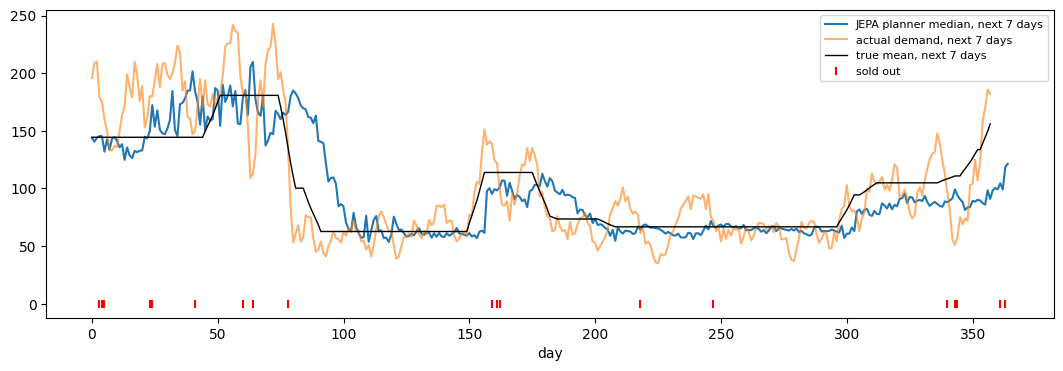

In [20]:
VARIANT = "no_fee"
if VARIANT in summaries:
    sv = summaries[VARIANT]
    bv = analysis.best_textbook(ROOTS[VARIANT])
    mv = analysis.score_matrix(sv).dropna()
    dv = (mv["jepa"] - mv[bv]).sort_values()
    SEED_V = int(dv.index[0])
    ARMS_V = ["jepa", bv, "planner_oracle"]
    tsv = data.load_timeseries(ROOTS[VARIANT], split="eval", method=ARMS_V, world_seed=SEED_V)
    display(sv[(sv["split"] == "eval") & (sv["world_seed"] == SEED_V)].set_index("method")
            [["score", "order_days", "fees", "holding_cost", "lost_units", "delivery_lag", "cv", "holding_rate"]].loc[ARMS_V])
    analysis.plot_world(tsv, SEED_V, 0, ARMS_V, days=(0, 120))
    analysis.plot_forecast(tsv, SEED_V, 0, "jepa")

In [21]:
for v in ["one_product", "no_fee"]:
    if v in ROOTS and ROOTS[v].exists():
        shv, agree_v = shadow_agreement(ROOTS[v])
        if agree_v is not None:
            print(v); display(agree_v)

one_product


,planner_oracle,tuned_periodic_order_up_to,tuned_eoq,tuned_eoq_joint,jepa (driver)
orders on same day (share of driver order days),0.85,0.14,0.93,0.89,1.00
mean units when ordering,165.20,83.19,213.19,208.76,159.69
order days per product-year,27.75,35.67,40.75,37.50,28.50


no_fee


,planner_oracle,tuned_periodic_order_up_to,tuned_eoq,tuned_eoq_joint,jepa (driver)
orders on same day (share of driver order days),0.87,0.91,0.99,0.99,1.00
mean units when ordering,14.55,34.98,26.40,26.25,15.04
order days per product-year,281.73,312.73,352.27,352.12,312.94


## 12 · Conclusions

500 eval worlds per world type, every arm paired by world. Differences are points of margin capture, with 95% bootstrap intervals.

| world | JEPA − best textbook rule (tuned joint EOQ in all three) | JEPA wins | JEPA − planner + moving average | oracle planner − JEPA | JEPA − direct |
| --- | --- | --- | --- | --- | --- |
| base (4 products, fee 50) | **+0.40** [+0.37, +0.43] | 94% | +0.35 | +0.38 | −0.00 |
| one product, fee 50 | **+0.06** [+0.02, +0.11] | 53% | +0.24 | +0.22 | −0.01 |
| four products, no fee | **−0.05** [−0.09, −0.01] | 39% | +0.65 | +0.73 | −0.01 |

1. **The earlier "+2.4 points over textbook" was mostly the fee.** Against the four engine rules, which trigger per product and ignore fee and holding rate, JEPA still wins by 2–3 points in the base world. But a textbook EOQ rule with a joint trigger orders the same way and closes 2.1 of those points without any learning. The fair base-world lead is +0.40.
2. **Without the fee, JEPA ties the best textbook rule.**
   - One product: +0.06, winning about half the worlds.
   - No fee: −0.05. Here EOQ becomes a daily base-stock rule with a high tuned safety factor (z ≈ 3.5). It loses half as many sales as JEPA (0.47% vs 1.0%) and holds 47% more stock; that trade wins narrowly.
3. **The forecast is worth something, but only against a weak forecast.** Inside the same planner, the learned forecast beats a 28-day moving average in every world (+0.24 to +0.65). A well-tuned textbook safety stock matches it.
4. **The JEPA latent objective adds nothing.** The same network trained on the quantile loss alone (`direct`) is within ±0.01 points in all three worlds.
5. **Headroom remains.** The planner with the true demand distribution beats the best textbook rule in every world (+0.78, +0.28, +0.67). A better forecaster would gain up to the oracle-minus-JEPA gap (+0.38, +0.22, +0.73), but this forecaster does not capture it.

**Checks behind these numbers.**
- A code review found no information leak. Policies see only censored sales; train, tune, and eval worlds are disjoint; and arms are paired.
- The planner's imagined recursion equals a real simulator run on the same demand, including when cash and shelf bind (`test_imagined_equity_matches_the_sim_on_the_realised_demand`).
- Textbook rules are tuned on separate tune worlds per world type. The baseline is chosen on those tune scores.
- **Sensitivity check (32 tune worlds per world type):** sampling the planner's demand paths with exponential upper tails and adding a 0.999 service level changed JEPA by at most 0.03 points, so the planner's tail handling does not explain the no-fee result.
- Widening the EOQ safety-factor search from 3.5 to 6 left its optimum at about 3.5.